# Customer Support Ticket Classification

This notebook trains an LSTM neural network to categorize support tickets and predict their priority based on the text description.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import warnings


## 1. Load and Prepare Data
We load the dataset and perform basic text cleaning (lowercasing and removing punctuation) on the ticket descriptions.

In [7]:

df = pd.read_csv('customer_support_tickets.csv')

# Select relevant columns and drop empty rows
df = df[['Ticket Description', 'Ticket Type', 'Ticket Priority']].dropna()

def clean_text(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    return text

df['clean_desc'] = df['Ticket Description'].apply(clean_text)
df.head()

,Ticket Description,Ticket Type,Ticket Priority,clean_desc
0,I'm having an issue with the {product_purchase...,Technical issue,Critical,im having an issue with the product_purchased ...
1,I'm having an issue with the {product_purchase...,Technical issue,Critical,im having an issue with the product_purchased ...
2,I'm facing a problem with my {product_purchase...,Technical issue,Low,im facing a problem with my product_purchased ...
3,I'm having an issue with the {product_purchase...,Billing inquiry,Low,im having an issue with the product_purchased ...
4,I'm having an issue with the {product_purchase...,Billing inquiry,Low,im having an issue with the product_purchased ...


## 2. Text Preprocessing (Tokenization and Padding)
Neural networks can only process numbers, not strings. We will use a `Tokenizer` to convert each word into a unique integer. Then, we `pad_sequences` so that every ticket description is exactly the same length (100 words).

In [8]:
# Encode the target labels (Categories -> Numbers)
type_encoder = LabelEncoder()
priority_encoder = LabelEncoder()

df['Type_Encoded'] = type_encoder.fit_transform(df['Ticket Type'])
df['Priority_Encoded'] = priority_encoder.fit_transform(df['Ticket Priority'])

MAX_WORDS = 10000
MAX_LEN = 100

# Initialize and fit tokenizer
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_desc'])

# Convert text to sequences and pad them
sequences = tokenizer.texts_to_sequences(df['clean_desc'])
X_padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

print(f"Shape of padded text data: {X_padded.shape}")

Shape of padded text data: (8469, 100)


## 3. Build Neural Network Architecture
We create a reusable function to build our LSTM model.
*   **Embedding Layer**: Maps integer tokens to dense vectors.
*   **LSTM Layer**: Processes the sequence to understand context.
*   **Dense Layer**: Outputs the probability of each category.

In [12]:
def build_lstm_model(vocab_size, max_length, num_classes):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length, mask_zero=True),
        LSTM(64, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

def plot_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


## 4. Train and Evaluate Ticket Category Model
First, we predict the `Ticket Type` (e.g., Billing, Technical issue).

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.7569 - loss: 0.6890 - val_accuracy: 0.9652 - val_loss: 0.1235
Epoch 2/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9587 - loss: 0.1224 - val_accuracy: 0.9675 - val_loss: 0.0868
Epoch 3/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9616 - loss: 0.1012 - val_accuracy: 0.9646 - val_loss: 0.0851
Epoch 4/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9641 - loss: 0.0890 - val_accuracy: 0.9693 - val_loss: 0.0858
Epoch 5/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9672 - loss: 0.0797 - val_accuracy: 0.9669 - val_loss: 0.0853
Epoch 6/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9723 - loss: 0.0697 - val_accuracy: 0.9687 - val_loss: 0.0901
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

Classification Report: Ticket Category

                      precision    recall  f1-score   support

     Billing inquiry       0.94      0.98      0.96       357
Cancellation request       0.94     

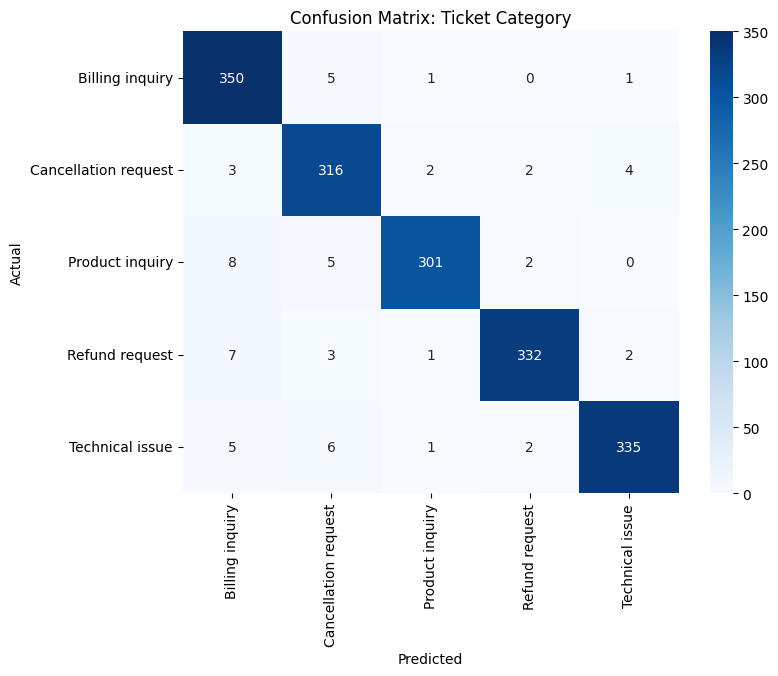

In [13]:
y_type = df['Type_Encoded'].values
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_padded, y_type, test_size=0.2, random_state=42)

num_type_classes = len(type_encoder.classes_)
type_model = build_lstm_model(MAX_WORDS, MAX_LEN, num_type_classes)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
# Train using early stopping to prevent overfitting
history_type = type_model.fit(X_train_t, y_train_t, epochs=20, batch_size=32, validation_data=(X_test_t, y_test_t), callbacks=[early_stop])

# Evaluate
type_preds = np.argmax(type_model.predict(X_test_t), axis=-1)
print("\nClassification Report: Ticket Category\n")
print(classification_report(y_test_t, type_preds, target_names=type_encoder.classes_))
plot_confusion_matrix(y_test_t, type_preds, type_encoder.classes_, "Confusion Matrix: Ticket Category")

## 5. Train and Evaluate Ticket Priority Model
Next, we use a separate LSTM model to predict the `Ticket Priority` (e.g., High, Low) directly from the text description.

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8450 - loss: 0.4349 - val_accuracy: 0.9628 - val_loss: 0.0819
Epoch 2/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9665 - loss: 0.0803 - val_accuracy: 0.9658 - val_loss: 0.0824
Epoch 3/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9696 - loss: 0.0714 - val_accuracy: 0.9652 - val_loss: 0.0830
Epoch 4/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9697 - loss: 0.0688 - val_accuracy: 0.9646 - val_loss: 0.0847
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Classification Report: Ticket Priority

              precision    recall  f1-score   support

    Critical       0.94      0.97      0.96       411
        High       0.93      0.96      0.95       409
         Low       0.99      0.96      0.97       415
      Medium       0.99      0.96      0.97       459

    accuracy                           0.96      1694
   macro avg       0.96      0.96      0.96      1694
weighted avg       0.96      0.96     

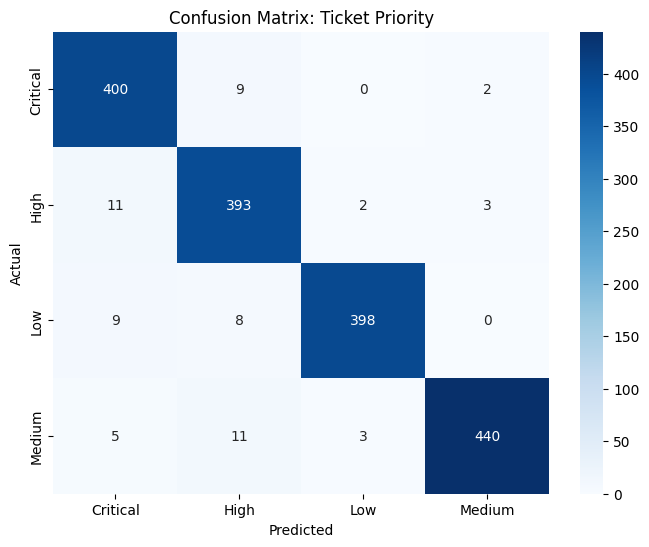

In [14]:
y_priority = df['Priority_Encoded'].values
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_padded, y_priority, test_size=0.2, random_state=42)

num_priority_classes = len(priority_encoder.classes_)
priority_model = build_lstm_model(MAX_WORDS, MAX_LEN, num_priority_classes)

history_priority = priority_model.fit(X_train_p, y_train_p, epochs=20, batch_size=32, validation_data=(X_test_p, y_test_p), callbacks=[early_stop])

# Evaluate
priority_preds = np.argmax(priority_model.predict(X_test_p), axis=-1)
print("\nClassification Report: Ticket Priority\n")
print(classification_report(y_test_p, priority_preds, target_names=priority_encoder.classes_))
plot_confusion_matrix(y_test_p, priority_preds, priority_encoder.classes_, "Confusion Matrix: Ticket Priority")

## 6. Summary
The LSTM model is able to pick up on the context of the text to categorize the ticket and assign it a priority level. This type of pipeline can be used to automatically route tickets to the correct department.